### Dataset setting and data preprocessing

In [1]:
import pandas as pd
import kagglehub
import os

# Reference to the downloaded path 
path = kagglehub.dataset_download("doanquanvietnamca/liar-dataset")


# Load train set and test set + header definition
col_names = ['id', 'label', 'statement', 'subject', 'speaker', 'job', 'state', 'party', 
             'barely_true', 'false', 'half_true', 'mostly_true', 'pants_on_fire', 'context']

df_train = pd.read_csv(os.path.join(path, 'train.tsv'), sep='\t', names=col_names, header=None)
df_test = pd.read_csv(os.path.join(path, 'test.tsv'), sep='\t', names=col_names, header=None)

# Select 'statement' column and 'label' column
df_train = df_train[['statement', 'label']].dropna() # train set
df_test = df_test[['statement', 'label']].dropna() # test set

c:\Users\Utente\AppData\Local\Programs\Python\Python310\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### Count statements

In [2]:
print(df_train.count())
print(df_test.count())

statement    10240
label        10240
dtype: int64
statement    1267
label        1267
dtype: int64


In [2]:
# 6 class mapping (false, half-true, mostly-true, true, barely-true, pants-on-fire):
# 'true', 'mostly_true', 'hald-true -> 1 (true)
#  else -> 0 (false)
def map_label(label):
    if label in ['true', 'mostly-true', 'half-true']:
        return 1 
    else:
        return 0  

df_train['binary_label'] = df_train['label'].apply(map_label)
df_test['binary_label'] = df_test['label'].apply(map_label)

# Compute Neg Rate
neg_rate_train = (df_train['binary_label'] == 0).mean() * 100
neg_rate_test = (df_test['binary_label'] == 0).mean() * 100

print(f"Train Set Neg Rate: {neg_rate_train:.2f}%")
print(f"Test Set Neg Rate:  {neg_rate_test:.2f}%")
        

# Dataset preparation
df_all = pd.concat([df_train, df_test], ignore_index=True)
df_all['binary_label'] = df_all['label'].apply(map_label)

X = df_all['statement'].values
y = df_all['binary_label'].values

Train Set Neg Rate: 43.83%
Test Set Neg Rate:  43.65%


### Utility Functions

In [5]:
import json
import ollama
from tqdm import tqdm

# Utility functions to build prompts: 

# Plain text prompt
def generate_prompt_plaintext(news_item): 
     return ( 
     "Act as an expert fact-checker. " 
     "Evaluate the truthfulness of the provided news text. " 
     "Answer strictly choosing only between the options 'True' or 'False'.\n\n" f"News text: {news_item}\n\n" "Answer:" 
     )

# Markdown prompt
def generate_prompt_markdown(news_item):
    return f"""### Role
Act as an expert fact-checker.

### Task
Evaluate the truthfulness of the provided news text.

### Constraints
Answer strictly choosing only between the options 'True' or 'False'.

### News text
> {news_item}

### Answer:
"""

# JSON prompt
def generate_prompt_json(news_item):
    structure = {
        "role": "Act as an expert fact-checker.",
        "task": "Evaluate the truthfulness of the provided news text.",
        "constraints": {
            "allowed_answers": ["True", "False"],
            "instruction": "Output strictly 'True' or 'False'.",
        },
        "input_data": {"news_text": news_item},
    }
    return json.dumps(structure, ensure_ascii=False)


def ask_ollama(prompt, model="llama3.1"):
    try:
        response = ollama.chat(
            model=model,
            messages=[{'role': 'user', 'content': prompt}],
            keep_alive=-1,  # Model always in RAM
            options={
                'temperature': 0.0,
                'top_p': 1.0,
                'seed': 42,
                'num_ctx': 2048,     
                'num_thread': 2,      
            }
        )
        return response['message']['content'].strip()
    except Exception as e:
        return f"ERROR: {str(e)}"


In [3]:
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score
import scipy.stats as stats
from sklearn.feature_extraction.text import TfidfVectorizer
import numpy as np

def evaluate_model(model_class, model_kwargs, X, y, n_splits=10, n_repeats=4, n_bootstraps=10000, random_state=43):
    rskf = RepeatedStratifiedKFold(
        n_splits=n_splits, n_repeats=n_repeats, random_state=random_state
    )
    metrics = {'accuracy': [], 'precision': [], 'recall': [], 'f1': []}

    for train_idx, test_idx in rskf.split(X, y):
        X_train_fold, X_test_fold = X[train_idx], X[test_idx]
        y_train_fold, y_test_fold = y[train_idx], y[test_idx]

        # TF-IDF fit on train
        vectorizer = TfidfVectorizer(max_features=5000)
        X_train_tfidf = vectorizer.fit_transform(X_train_fold)
        X_test_tfidf = vectorizer.transform(X_test_fold)

        # Initialization and training
        model = model_class(**model_kwargs)
        model.fit(X_train_tfidf, y_train_fold)

        y_pred = model.predict(X_test_tfidf)

        # Metrics computation
        metrics['accuracy'].append(accuracy_score(y_test_fold, y_pred))
        metrics['precision'].append(
            precision_score(y_test_fold, y_pred, zero_division=0)
        )
        metrics['recall'].append(
            recall_score(y_test_fold, y_pred, zero_division=0)
        )
        metrics['f1'].append(
            f1_score(y_test_fold, y_pred, average='macro')
        )

    # IC 95% - Bootstrap
    summary_results = []
    rng = np.random.default_rng(random_state)

    for metric_name, values in metrics.items():

        # Original sample mean
        values_arr = np.array(values)
        mean_val = np.mean(values_arr)

        # Bootstrap Resample With Replacement
        boot_samples = rng.choice(
            values_arr, size=(n_bootstraps, len(values_arr)), replace=True
        )

        # n_bootstraps mean computation
        boot_means = np.mean(boot_samples, axis=1)

        # the 2.5th and 97.5th percentiles extraction
        ci_lower = np.percentile(boot_means, 2.5)
        ci_upper = np.percentile(boot_means, 97.5)

        summary_results.append(
            {
                'Metric': metric_name,
                'Mean': mean_val,
                'CI_Lower': ci_lower,
                'CI_Upper': ci_upper,
            }
        )

    return pd.DataFrame(summary_results), pd.DataFrame(metrics)

### SVM and LR - globally

In [4]:
import os
import pandas as pd
from sklearn.svm import LinearSVC
from sklearn.linear_model import LogisticRegression

raw_csv_path = 'model_cross_validation_raw_results.csv'
summary_csv_path = 'model_performance_summary.csv'

if os.path.exists(raw_csv_path) and os.path.exists(summary_csv_path):
    df_results_raw = pd.read_csv(raw_csv_path)
    df_summary = pd.read_csv(summary_csv_path)

else:
    # SVM training and testing
    summary_svm, raw_svm = evaluate_model(
        LinearSVC,
        {'random_state': 42, 'dual': 'auto', 'class_weight': 'balanced'},
        X,
        y,
    )

    # LR training and testing
    summary_lr, raw_lr = evaluate_model(
        LogisticRegression,
        {
            'random_state': 42,
            'class_weight': 'balanced',
            'max_iter': 1000,
        },
        X,
        y,
    )

    # Model identification
    summary_svm['Model'] = 'Linear SVM'
    summary_lr['Model'] = 'Logistic Regression'
    raw_svm['Model'] = 'Linear SVM'
    raw_lr['Model'] = 'Logistic Regression'

    # Results Concatenation
    df_summary = pd.concat([summary_svm, summary_lr], ignore_index=True)
    df_results_raw = pd.concat([raw_svm, raw_lr], ignore_index=True)

    df_results_raw.to_csv(raw_csv_path, index=False)
    df_summary.to_csv(summary_csv_path, index=False)

    print("Done")

In [5]:
# Final table
df_summary.sort_values(by=['Metric', 'Model'])

,Metric,Mean,CI_Lower,CI_Upper,Model
0,accuracy,0.584774,0.580514,0.588907,Linear SVM
4,accuracy,0.606130,0.601194,0.611323,Logistic Regression
3,f1,0.580435,0.576072,0.584588,Linear SVM
7,f1,0.603180,0.598289,0.608282,Logistic Regression
1,precision,0.636224,0.632098,0.640157,Linear SVM
5,precision,0.660589,0.655935,0.665402,Logistic Regression
2,recall,0.609918,0.604451,0.615332,Linear SVM
6,recall,0.615216,0.609009,0.621523,Logistic Regression


In [6]:
# test set
df_test_sample = df_test.sample(n=300, random_state=42).copy()
neg_rate_test_sample = (df_test_sample['binary_label'] == 0).mean() * 100

print(f"Test Set Neg Rate (300 sample): {neg_rate_test_sample:.2f}%")

Test Set Neg Rate (300 sample): 45.33%


In [7]:
import os
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_recall_fscore_support
from sklearn.svm import LinearSVC


X_train_text = df_train['statement'].values
y_train = df_train['binary_label'].values

X_test_text = df_test_sample['statement'].values
y_test = df_test_sample['binary_label'].values

vectorizer = TfidfVectorizer(max_features=5000)
X_train_tfidf = vectorizer.fit_transform(X_train_text)
X_test_tfidf = vectorizer.transform(X_test_text)

# --- MODEL 1: Linear SVM ---
svm_model = LinearSVC(random_state=42, dual='auto', class_weight='balanced')
svm_model.fit(X_train_tfidf, y_train)

decision_scores = svm_model.decision_function(X_test_tfidf)
y_pred_svm = svm_model.predict(X_test_tfidf)

y_true = df_test_sample['binary_label']
acc_svm = accuracy_score(y_true, y_pred_svm)
prec_svm, rec_svm, f1_svm, _ = precision_recall_fscore_support(y_true, y_pred_svm, average='binary')

print("--- Linear SVM (raw text) ---")
print(f"Accuracy:  {acc_svm:.4f}")
print(f"Precision: {prec_svm:.4f}")
print(f"Recall:    {rec_svm:.4f}")
print(f"F1-Score:  {f1_svm:.4f}")

svm_metrics = [
    {'Model': 'Linear SVM', 'Format': fmt, 'Accuracy': acc_svm, 'Precision': prec_svm, 'Recall': rec_svm, 'F1-Score': f1_svm}
    for fmt in ['Plaintext', 'Markdown', 'JSON']
]

# --- MODEL 2: Logistic Regression ---
lr_model = LogisticRegression(random_state=42, class_weight='balanced', max_iter=1000)
lr_model.fit(X_train_tfidf, y_train)

probabilities = lr_model.predict_proba(X_test_tfidf)
y_pred_lr = lr_model.predict(X_test_tfidf)

y_true = df_test_sample['binary_label']
acc_lr = accuracy_score(y_true, y_pred_lr)
prec_lr, rec_lr, f1_lr, _ = precision_recall_fscore_support(y_true, y_pred_lr, average='binary')

print("--- Logistic Regression (raw text) ---")
print(f"Accuracy:  {acc_lr:.4f}")
print(f"Precision: {prec_lr:.4f}")
print(f"Recall:    {rec_lr:.4f}")
print(f"F1-Score:  {f1_lr:.4f}")

lr_metrics = [
    {'Model': 'Logistic Regression', 'Format': fmt, 'Accuracy': acc_lr, 'Precision': prec_lr, 'Recall': rec_lr, 'F1-Score': f1_lr}
    for fmt in ['Plaintext', 'Markdown', 'JSON']
]


--- Linear SVM (raw text) ---
Accuracy:  0.6067
Precision: 0.6513
Recall:    0.6037
F1-Score:  0.6266
--- Logistic Regression (raw text) ---
Accuracy:  0.6367
Precision: 0.6821
Recall:    0.6280
F1-Score:  0.6540


### Bootstrap Percentile - Sample 300

In [8]:
import numpy as np
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score

def bootstrap_sample_metrics(
    y_true, y_pred, n_bootstraps=10000, random_state=42
):
    rng = np.random.default_rng(random_state)
    n_samples = len(y_true)

    acc_boots, prec_boots, rec_boots, f1_boots = [], [], [], []

    for _ in range(n_bootstraps):
        idx = rng.choice(n_samples, size=n_samples, replace=True)
        y_t_boot, y_p_boot = y_true[idx], y_pred[idx]

        acc_boots.append(accuracy_score(y_t_boot, y_p_boot))
        prec_boots.append(precision_score(y_t_boot, y_p_boot, zero_division=0))
        rec_boots.append(recall_score(y_t_boot, y_p_boot, zero_division=0))
        f1_boots.append(f1_score(y_t_boot, y_p_boot, average='macro'))

    return {
        'acc_lower': np.percentile(acc_boots, 2.5),
        'acc_upper': np.percentile(acc_boots, 97.5),
        'prec_lower': np.percentile(prec_boots, 2.5),
        'prec_upper': np.percentile(prec_boots, 97.5),
        'rec_lower': np.percentile(rec_boots, 2.5),
        'rec_upper': np.percentile(rec_boots, 97.5),
        'f1_lower': np.percentile(f1_boots, 2.5),
        'f1_upper': np.percentile(f1_boots, 97.5),
    }


# IC computation
ic_svm_300 = bootstrap_sample_metrics(y_test, y_pred_svm)
ic_lr_300 = bootstrap_sample_metrics(y_test, y_pred_lr)

### LLM Testing: llama3.1

In [6]:
model_chosen = "llama3.1"
OUTPUT_FILE = "results_llama3.csv"

# Check if results already exist
if os.path.exists(OUTPUT_FILE):
    df_existing = pd.read_csv(OUTPUT_FILE)
    done = set(df_existing['statement'])
    print(f"{len(done)} results found. Restarting from where I left...")
else:
    df_existing = pd.DataFrame()
    done = set()

for idx, row in tqdm(df_test_sample.iterrows(), total=len(df_test_sample)):
    text = row['statement']

    if text in done:
        continue

    resp_plain = ask_ollama(generate_prompt_plaintext(text), model_chosen)
    resp_md = ask_ollama(generate_prompt_markdown(text), model_chosen)
    resp_json = ask_ollama(generate_prompt_json(text), model_chosen)
    
    new_row = pd.DataFrame([{
        'statement': text,
        'true_label': row['binary_label'],
        'res_plaintext': resp_plain,
        'res_markdown': resp_md,
        'res_json': resp_json
    }])

    header_new_row = not os.path.exists(OUTPUT_FILE)
    new_row.to_csv(OUTPUT_FILE, mode='a', index=False, header=header_new_row)
    done.add(text)

print("Test completed! Results saved in 'results_llama3.csv'")

300 results found. Restarting from where I left...


  0%|          | 0/300 [00:00<?, ?it/s]

100%|██████████| 300/300 [00:00<00:00, 6669.02it/s]

Test completed! Results saved in 'results_llama3.csv'


### LLM Testing: Mistral

In [7]:
model_chosen = "mistral"
OUTPUT_FILE = "results_mistral.csv"

if os.path.exists(OUTPUT_FILE):
    df_existing = pd.read_csv(OUTPUT_FILE)
    done = set(df_existing['statement'])
    print(f"{len(done)} results found. Restarting from where I left...")
else:
    df_existing = pd.DataFrame()
    done = set()

for idx, row in tqdm(df_test_sample.iterrows(), total=len(df_test_sample)):
    text = row['statement']

    if text in done:
        continue

    resp_plain = ask_ollama(generate_prompt_plaintext(text), model_chosen)
    resp_md = ask_ollama(generate_prompt_markdown(text), model_chosen)
    resp_json = ask_ollama(generate_prompt_json(text), model_chosen)
    
    new_row = pd.DataFrame([{
        'statement': text,
        'true_label': row['binary_label'],
        'res_plaintext': resp_plain,
        'res_markdown': resp_md,
        'res_json': resp_json
    }])

    header_new_row = not os.path.exists(OUTPUT_FILE)
    new_row.to_csv(OUTPUT_FILE, mode='a', index=False, header=header_new_row)
    done.add(text)

print("Test completed! Results saved in 'results_mistral.csv'")

300 results found. Restarting from where I left...


  0%|          | 0/300 [00:00<?, ?it/s]

100%|██████████| 300/300 [00:00<00:00, 4615.41it/s]

Test completed! Results saved in 'results_mistral.csv'


### LLM Testing: Qwen2.5

In [8]:
model_chosen = "qwen2.5:7b"
OUTPUT_FILE = "results_qwen2.csv"

if os.path.exists(OUTPUT_FILE):
    df_existing = pd.read_csv(OUTPUT_FILE)
    done = set(df_existing['statement'])
    print(f"{len(done)} results found. Restarting from where I left...")
else:
    df_existing = pd.DataFrame()
    done = set()

for idx, row in tqdm(df_test_sample.iterrows(), total=len(df_test_sample)):
    text = row['statement']

    if text in done:
        continue

    resp_plain = ask_ollama(generate_prompt_plaintext(text), model_chosen)
    resp_md = ask_ollama(generate_prompt_markdown(text), model_chosen)
    resp_json = ask_ollama(generate_prompt_json(text), model_chosen)
    
    new_row = pd.DataFrame([{
        'statement': text,
        'true_label': row['binary_label'],
        'res_plaintext': resp_plain,
        'res_markdown': resp_md,
        'res_json': resp_json
    }])

    header_new_row = not os.path.exists(OUTPUT_FILE)
    new_row.to_csv(OUTPUT_FILE, mode='a', index=False, header=header_new_row)
    done.add(text)

print("Test completed! Results saved in 'results_qwen2.csv'")

300 results found. Restarting from where I left...


100%|██████████| 300/300 [00:00<00:00, 5769.15it/s]

Test completed! Results saved in 'results_qwen2.csv'


### LLM Testing: gemma2

In [9]:
model_chosen = "gemma2:9b"
OUTPUT_FILE = "results_gemma2.csv"

if os.path.exists(OUTPUT_FILE):
    df_existing = pd.read_csv(OUTPUT_FILE)
    done = set(df_existing['statement'])
    print(f"{len(done)} results found. Restarting from where I left...")
else:
    df_existing = pd.DataFrame()
    done = set()

for idx, row in tqdm(df_test_sample.iterrows(), total=len(df_test_sample)):
    text = row['statement']

    if text in done:
        continue

    resp_plain = ask_ollama(generate_prompt_plaintext(text), model_chosen)
    resp_md = ask_ollama(generate_prompt_markdown(text), model_chosen)
    resp_json = ask_ollama(generate_prompt_json(text), model_chosen)
    
    new_row = pd.DataFrame([{
        'statement': text,
        'true_label': row['binary_label'],
        'res_plaintext': resp_plain,
        'res_markdown': resp_md,
        'res_json': resp_json
    }])

    header_new_row = not os.path.exists(OUTPUT_FILE)
    new_row.to_csv(OUTPUT_FILE, mode='a', index=False, header=header_new_row)
    done.add(text)

print("Test completed! Results saved in 'results_gemma2.csv'")

300 results found. Restarting from where I left...


  0%|          | 0/300 [00:00<?, ?it/s]

100%|██████████| 300/300 [00:00<00:00, 6520.18it/s]

Test completed! Results saved in 'results_gemma2.csv'


### Evaluation Metrics

In [ ]:
import pandas as pd
import re
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

# Results loading
df_llama = pd.read_csv("results_llama3.csv")
df_mistral= pd.read_csv("results_mistral.csv")
df_qwen = pd.read_csv("results_qwen2.csv")
df_gemma2 = pd.read_csv("results_gemma2.csv")


# Utility function to convert LLM answer to False/True/None
def parse_llm_response(text: str) -> bool | None:

    # 1. Direct type matching
    if isinstance(text, bool):
        return text

    if pd.isna(text):
        return None  

    text = str(text)

    # 2. Input Validation
    if not text.strip():
        return None

    # 3. Preprocessing
    text_clean = text.strip().lower()

    # 4. JSON Pattern Matching
    try:
        data = json.loads(text)
        if isinstance(data, dict) and "allowed_answer" in data:
            ans = str(data["allowed_answer"]).strip().lower()
            if ans == "true":
                return True
            if ans == "false":
                return False
    except json.JSONDecodeError:
        pass  

    match_json_key = re.search(
        r'"allowed_answer"\s*:\s*"?\s*(true|false)\s*"?', text_clean
    )
    if match_json_key:
        return match_json_key.group(1) == "true"

    # 5. LaTeX Extraction
    latex_match = re.search(r'\\boxed\{\s*(?:\\text\{)?\s*(true|false)\s*\}?\s*\}', text_clean)
    if latex_match:
        return latex_match.group(1) == "true"

    # 6. Direct Matching
    clean_word = re.sub(r'^[^\w\s]+|[^\w\s]+$', '', text_clean).strip()
    if clean_word == "true":
        return True
    if clean_word == "false":
        return False

    # 7. Refusal and Uncertainity detection
    refusal_patterns = [
        r'cannot\s+(definitively\s+)?say',
        r'cannot\s+determine',
        r'cannot\s+verify',
        r'unable\s+to\s+(determine|verify|say|confirm)',
        r'insufficient\s+information',
        r'not\s+enough\s+context',
        r'both\s+true\s+and\s+false',
        r'neither\s+true\s+nor\s+false',

        r"can'?t\s+assist\s+with\s+(that|this)",
        r"cannot\s+assist\s+with\s+(that|this)",
        r"can'?t\s+fulfill\s+this\s+request",
        r"i\s+am\s+unable\s+to\s+process",
        r"as\s+an\s+ai\b"
    ]
    if any(re.search(pattern, text_clean) for pattern in refusal_patterns):
        return None

    # 8. Long and Contextual answers
    matches = list(re.finditer(r'\b(not\s+true|not\s+false|true|false)\b', text_clean))
    
    if matches:
        last_match = matches[-1].group(1)
        if last_match in ['true', 'not false']:
            return True
        if last_match in ['false', 'not true']:
            return False

    # 9. Default Fallback
    return None

def compute_evaluation_metrics (df, model):
    df['pred_plaintext'] = df['res_plaintext'].apply(parse_llm_response)
    df['pred_markdown'] = df['res_markdown'].apply(parse_llm_response)
    df['pred_json'] = df['res_json'].apply(parse_llm_response)

    y_true = df['true_label']
    formats = {'Plaintext': df['pred_plaintext'], 'Markdown': df['pred_markdown'], 'JSON': df['pred_json']}

    metrics_list = []

    for format_name, y_pred in formats.items():
        # SELECT ONLY VALID ANSWER: if pred == None -> throw away
        valid_mask = y_pred.notna()
        
        y_true_valid = y_true[valid_mask]
        y_pred_valid = y_pred[valid_mask].astype(bool)
        
        parse_rate = (valid_mask.sum() / len(df)) * 100
        
        acc = accuracy_score(y_true_valid, y_pred_valid)
        prec, rec, f1, _ = precision_recall_fscore_support(y_true_valid, y_pred_valid, average='binary', zero_division=0)
        
        
        metrics_list.append({
            'Model': model,
            'Format': format_name,
            'Parse_Rate_%': parse_rate,
            'Accuracy': acc,
            'Precision': prec,
            'Recall': rec,
            'F1-Score': f1
        })
        
    return metrics_list


# Metrics evaluation for LLMs 
llama_metrics = compute_evaluation_metrics(df_llama, "Llama 3.1")
mistral_metrics = compute_evaluation_metrics(df_mistral, "Mistral")
qwen2_metrics = compute_evaluation_metrics(df_qwen, "Qwen2.5")
gemma2_metrics = compute_evaluation_metrics(df_gemma2, "Gemma2")

# df_metrics_total = pd.DataFrame(lr_metrics + svm_metrics + llama_metrics + mistral_metrics +  qwen2_metrics + gemma2_metrics)
df_metrics_llms = pd.DataFrame(llama_metrics + mistral_metrics + qwen2_metrics + gemma2_metrics)
df_metrics_total = pd.DataFrame (svm_metrics + lr_metrics + llama_metrics + mistral_metrics + qwen2_metrics + gemma2_metrics)

df_metrics_llms.sort_values(by=['Model'])

,Model,Format,Parse_Rate_%,Accuracy,Precision,Recall,F1-Score
9,Gemma2,Plaintext,98.666667,0.702703,0.561644,0.422680,0.482353
10,Gemma2,Markdown,100.000000,0.706667,0.571429,0.371134,0.450000
11,Gemma2,JSON,100.000000,0.703333,0.574074,0.319588,0.410596
0,Llama 3.1,Plaintext,97.666667,0.696246,0.605263,0.237113,0.340741
1,Llama 3.1,Markdown,100.000000,0.693333,0.619048,0.134021,0.220339
2,Llama 3.1,JSON,91.000000,0.527473,0.389222,0.706522,0.501931
3,Mistral,Plaintext,97.333333,0.654110,0.444444,0.297872,0.356688
4,Mistral,Markdown,100.000000,0.673333,0.489796,0.247423,0.328767
5,Mistral,JSON,100.000000,0.666667,0.473684,0.278351,0.350649
6,Qwen2.5,Plaintext,100.000000,0.693333,0.666667,0.103093,0.178571


### Stability and Robustness
#### Perfomance Stability: Perfomance Drop Rate

In [134]:
import pandas as pd

# Utility to compute Perfomance Drop Rate (PDR) for each model employed
# using Plaintext as F0 

def compute_pdr(df_metrics, baseline_format='Plaintext', metric_col='F1-Score'):
    results_pdr = []

    for model in df_metrics['Model'].unique():
        df_model = df_metrics[df_metrics['Model'] == model]
        
        f0_row = df_model[df_model['Format'] == baseline_format]
        
        if f0_row.empty:
            continue
            
        f1_f0 = f0_row[metric_col].values[0]

        for _, row in df_model.iterrows():
            format_k = row['Format']
            f1_fk = row[metric_col]
            
            if f1_f0 != 0:
                pdr_val = (f1_f0 - f1_fk) / f1_f0
            else:
                pdr_val = 0.0

            results_pdr.append({
                'Model': model,
                'Format_Confronted': f"{baseline_format} vs {format_k}",
                'Format_k': format_k,
                'F1_F0': f1_f0,
                'F1_Fk': f1_fk,
                'PDR': pdr_val,
                'PDR_Percentual': f"{pdr_val * 100:.2f}%"
            })

    return pd.DataFrame(results_pdr)

df_pdr = compute_pdr(df_metrics_llms, baseline_format='Plaintext', metric_col='F1-Score')
df_pdr.sort_values(by=['Model'])

,Model,Format_Confronted,Format_k,F1_F0,F1_Fk,PDR,PDR_Percentual
9,Gemma2,Plaintext vs Plaintext,Plaintext,0.482353,0.482353,0.000000,0.00%
10,Gemma2,Plaintext vs Markdown,Markdown,0.482353,0.450000,0.067073,6.71%
11,Gemma2,Plaintext vs JSON,JSON,0.482353,0.410596,0.148764,14.88%
0,Llama 3.1,Plaintext vs Plaintext,Plaintext,0.340741,0.340741,0.000000,0.00%
1,Llama 3.1,Plaintext vs Markdown,Markdown,0.340741,0.220339,0.353353,35.34%
2,Llama 3.1,Plaintext vs JSON,JSON,0.340741,0.501931,-0.473057,-47.31%
3,Mistral,Plaintext vs Plaintext,Plaintext,0.356688,0.356688,0.000000,0.00%
4,Mistral,Plaintext vs Markdown,Markdown,0.356688,0.328767,0.078278,7.83%
5,Mistral,Plaintext vs JSON,JSON,0.356688,0.350649,0.016929,1.69%
6,Qwen2.5,Plaintext vs Plaintext,Plaintext,0.178571,0.178571,0.000000,0.00%


#### Performance Consistency: Format Consistency, designed by Shu et al

In [ ]:
import pandas as pd
import numpy as np

# Compute Format Consistency (Couples and Total) for a specific model
# from a dataframe containing binary predictions (0 / 1).
def compute_format_consistency(df_results, model):
    # Helper function to compute Format Consistency between valid pairs
    def calc_pair_consistency(s1, s2):
        valid_mask = s1.notna() & s2.notna()
        n_valid = valid_mask.sum()
        if n_valid == 0:
            return np.nan
        return (
            s1[valid_mask].astype(bool) == s2[valid_mask].astype(bool)
        ).sum() / n_valid

    # 1. Pairwise consistency
    c_plain_md = calc_pair_consistency(
        df_results["pred_plaintext"], df_results["pred_markdown"]
    )
    c_plain_json = calc_pair_consistency(
        df_results["pred_plaintext"], df_results["pred_json"]
    )
    c_md_json = calc_pair_consistency(
        df_results["pred_markdown"], df_results["pred_json"]
    )

    # 2. Total consistency
    valid_all = (
        df_results["pred_plaintext"].notna()
        & df_results["pred_markdown"].notna()
        & df_results["pred_json"].notna()
    )

    df_valid_all = df_results[valid_all]
    n_all = len(df_valid_all)

    if n_all > 0:
        p_plain = df_valid_all["pred_plaintext"].astype(bool)
        p_md = df_valid_all["pred_markdown"].astype(bool)
        p_json = df_valid_all["pred_json"].astype(bool)

        same_total = ((p_plain == p_md) & (p_md == p_json)).sum() / n_all
        c_total_pct = f"{same_total * 100:.2f}%"
    else:
        same_total = np.nan
        c_total_pct = "N/A"

    return {
        "Model": model,
        "C(Plain, MD)": c_plain_md,
        "C(Plain, JSON)": c_plain_json,
        "C(MD, JSON)": c_md_json,
        "C_Total": same_total,
        "C_Total_Percentual": c_total_pct,
    }

res_llama = compute_format_consistency(df_llama, "Llama 3.1")
res_mistral = compute_format_consistency(df_mistral, "Mistral")
res_qwen2 = compute_format_consistency(df_qwen, "Qwen2.5")
res_gemma2 = compute_format_consistency(df_gemma2, "Gemma2")

df_consistency = pd.DataFrame([res_llama, res_mistral, res_qwen2, res_gemma2])
df_consistency.sort_values(by=['Model'])

,Model,"C(Plain, MD)","C(Plain, JSON)","C(MD, JSON)",C_Total,C_Total_Percentual
3,Gemma2,0.945946,0.915541,0.936667,0.898649,89.86%
0,Llama 3.1,0.894198,0.520446,0.435897,0.420074,42.01%
1,Mistral,0.863014,0.818493,0.833333,0.756849,75.68%
2,Qwen2.5,0.950000,0.960000,0.976667,0.943333,94.33%


#### Prediction Consistency: Cohen's Kappa

In [132]:
import pandas as pd
from sklearn.metrics import cohen_kappa_score

# Compute Cohen's Kappa between format couples (Plain vs MD, Plain vs JSON, MD vs JSON) 
def compute_cohen_kappa(df_results, model):
    pred_plain = df_results["pred_plaintext"]
    pred_md = df_results["pred_markdown"]
    pred_json = df_results["pred_json"]

    def safe_kappa(s1, s2):
       # select only valid results (not None)
        valid_mask = s1.notna() & s2.notna()

        if valid_mask.sum() == 0:
            return np.nan

        return cohen_kappa_score(
            s1[valid_mask].astype(bool), s2[valid_mask].astype(bool)
        )

    # Pairwise kappa
    k_plain_md = safe_kappa(pred_plain, pred_md)
    k_plain_json = safe_kappa(pred_plain, pred_json)
    k_md_json = safe_kappa(pred_md, pred_json)
    
    k_mean = np.nanmean([k_plain_md, k_plain_json, k_md_json])

    return {
        "Model": model,
        "Kappa(Plain, MD)": k_plain_md,
        "Kappa(Plain, JSON)": k_plain_json,
        "Kappa(MD, JSON)": k_md_json,
        "Average_Kappa": k_mean,
    }

res_kappa_llama = compute_cohen_kappa(df_llama, "Llama 3.1")
res_kappa_mistral = compute_cohen_kappa(df_mistral, "Mistral")
res_kappa_qwen2 = compute_cohen_kappa(df_qwen, "Qwen2.5")
res_kappa_gemma2 = compute_cohen_kappa(df_gemma2, "Gemma2")

df_kappa = pd.DataFrame([res_kappa_llama, res_kappa_mistral, res_kappa_qwen2, res_kappa_gemma2])
df_kappa.sort_values(by=['Model'])

,Model,"Kappa(Plain, MD)","Kappa(Plain, JSON)","Kappa(MD, JSON)",Average_Kappa
3,Gemma2,0.847511,0.750909,0.798558,0.798993
0,Llama 3.1,0.421133,0.175102,0.051185,0.215807
1,Mistral,0.559744,0.441138,0.427787,0.476223
2,Qwen2.5,0.545455,0.578947,0.787879,0.637427


#### Probability Shift / Drift: MAPS

In [133]:
import pandas as pd
import numpy as np

# Compute Mean Absolute Probability Shift (MAPS) between different prompt formats.
# Handles both continuous probabilities and binary predictions.
def compute_maps(df_results, model, prob_cols=("prob_plaintext", "prob_markdown", "prob_json")):
  
    # Helper function, compute mean only on valid couples
    def calc_pair_maps(s1, s2):
        valid_mask = s1.notna() & s2.notna()
        if valid_mask.sum() == 0:
            return np.nan

        v1 = s1[valid_mask].astype(float)
        v2 = s2[valid_mask].astype(float)

        return np.mean(np.abs(v1 - v2))

    # Continuous probabilities
    if all(col in df_results.columns for col in prob_cols):
        s_plain = df_results[prob_cols[0]]
        s_md = df_results[prob_cols[1]]
        s_json = df_results[prob_cols[2]]

    # Binary predictions
    elif "pred_plaintext" in df_results.columns:
        s_plain = df_results["pred_plaintext"]
        s_md = df_results["pred_markdown"]
        s_json = df_results["pred_json"]
    else:
        raise ValueError(
            f"Cannot find probabilities or binary columns {model}"
        )

    maps_plain_md = calc_pair_maps(s_plain, s_md)
    maps_plain_json = calc_pair_maps(s_plain, s_json)
    maps_md_json = calc_pair_maps(s_md, s_json)

    maps_total = np.nanmean([maps_plain_md, maps_plain_json, maps_md_json])

    return {
        "Model": model,
        "MAPS(Plain, MD)": maps_plain_md,
        "MAPS(Plain, JSON)": maps_plain_json,
        "MAPS(MD, JSON)": maps_md_json,
        "Average_MAPS": maps_total,
        "MAPS_Average_Percentual": (
            f"{maps_total * 100:.2f}%" if not np.isnan(maps_total) else "N/A"
        ),
    }

res_maps_llama = compute_maps(df_llama, "Llama 3.1")
res_maps_mistral = compute_maps(df_mistral, "Mistral")
res_maps_qwen2 = compute_maps(df_qwen, "Qwen2.5")
res_maps_gemma2 = compute_maps(df_gemma2, "Gemma2")

df_maps = pd.DataFrame([res_maps_llama, res_maps_mistral, res_maps_qwen2, res_maps_gemma2])
df_maps.sort_values(by=['Model'])

,Model,"MAPS(Plain, MD)","MAPS(Plain, JSON)","MAPS(MD, JSON)",Average_MAPS,MAPS_Average_Percentual
3,Gemma2,0.054054,0.084459,0.063333,0.067282,6.73%
0,Llama 3.1,0.105802,0.479554,0.564103,0.383153,38.32%
1,Mistral,0.136986,0.181507,0.166667,0.161720,16.17%
2,Qwen2.5,0.050000,0.040000,0.023333,0.037778,3.78%


### Plot: Accuracy and F1-Score for SVM and LR 

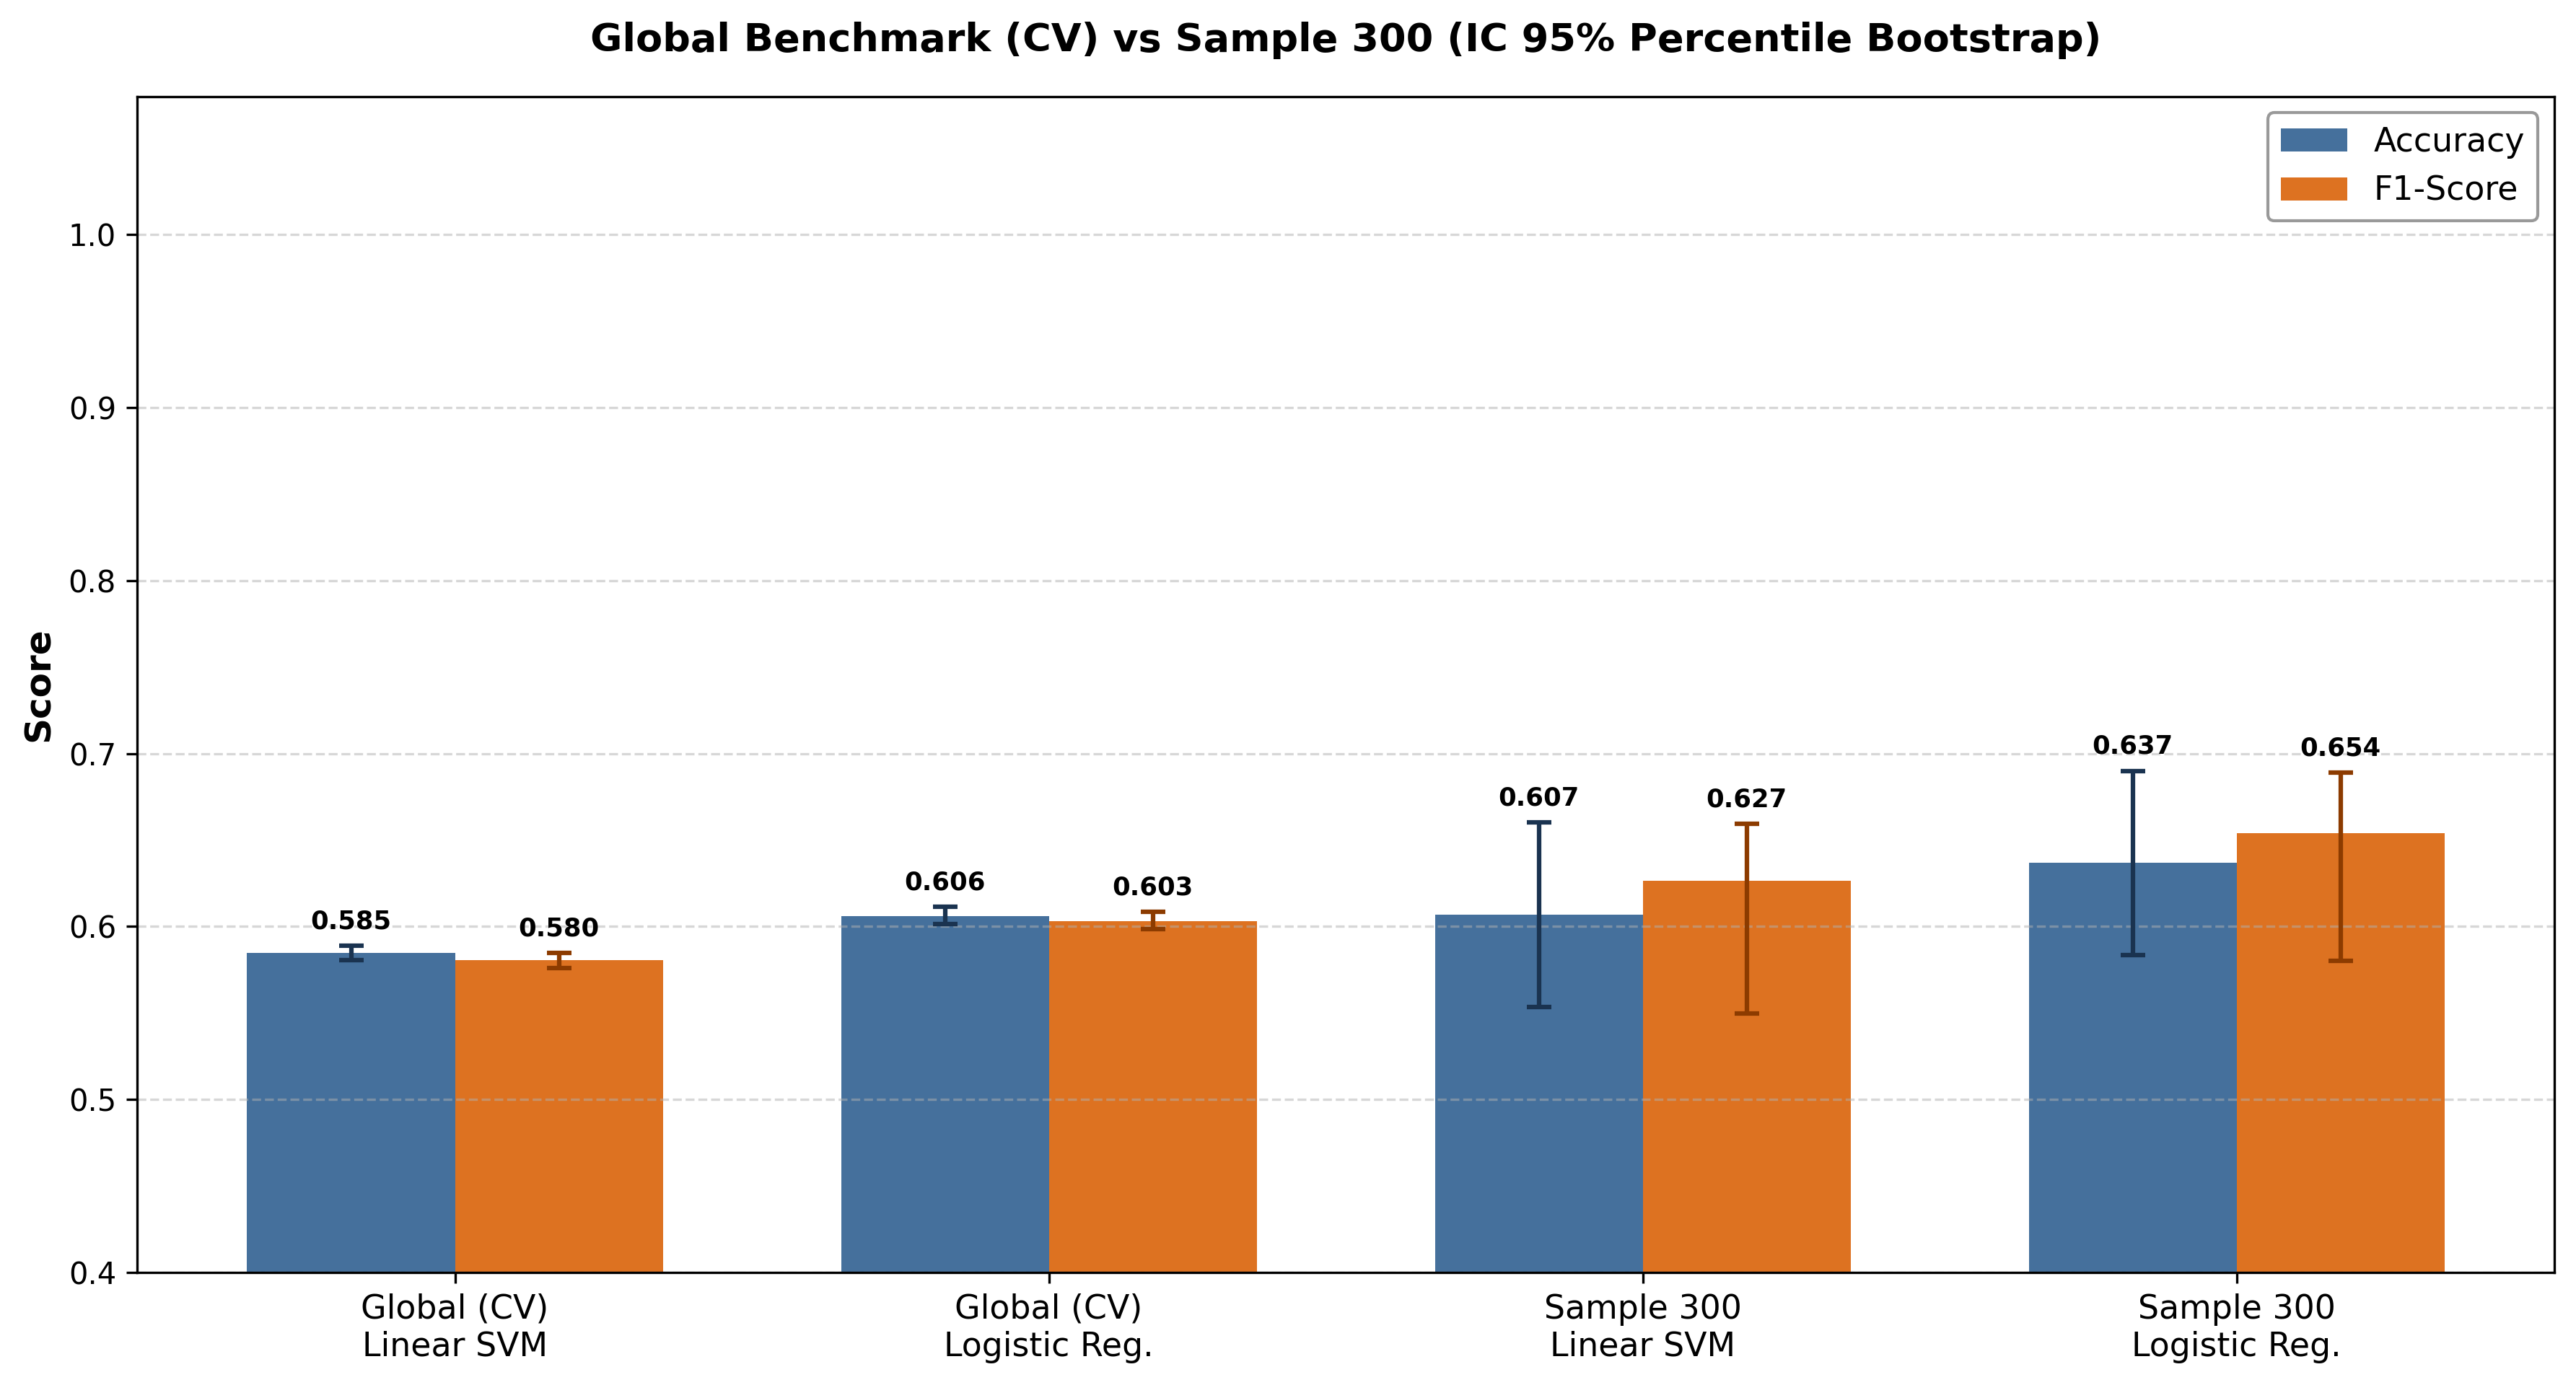

In [9]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# 1. Global dataframe extraction
svm_cv_acc = df_summary[
    (df_summary['Model'] == 'Linear SVM') & (df_summary['Metric'] == 'accuracy')
].iloc[0]
svm_cv_f1 = df_summary[
    (df_summary['Model'] == 'Linear SVM') & (df_summary['Metric'] == 'f1')
].iloc[0]

lr_cv_acc = df_summary[
    (df_summary['Model'] == 'Logistic Regression')
    & (df_summary['Metric'] == 'accuracy')
].iloc[0]
lr_cv_f1 = df_summary[
    (df_summary['Model'] == 'Logistic Regression')
    & (df_summary['Metric'] == 'f1')
].iloc[0]

# 2. Data preparation
data = [
    # Global CV 
    {
        'Label': 'Global (CV)\nLinear SVM',
        'Metric': 'Accuracy',
        'Score': svm_cv_acc['Mean'],
        'Low': svm_cv_acc['CI_Lower'],
        'High': svm_cv_acc['CI_Upper'],
    },
    {
        'Label': 'Global (CV)\nLinear SVM',
        'Metric': 'F1-Score',
        'Score': svm_cv_f1['Mean'],
        'Low': svm_cv_f1['CI_Lower'],
        'High': svm_cv_f1['CI_Upper'],
    },
    {
        'Label': 'Global (CV)\nLogistic Reg.',
        'Metric': 'Accuracy',
        'Score': lr_cv_acc['Mean'],
        'Low': lr_cv_acc['CI_Lower'],
        'High': lr_cv_acc['CI_Upper'],
    },
    {
        'Label': 'Global (CV)\nLogistic Reg.',
        'Metric': 'F1-Score',
        'Score': lr_cv_f1['Mean'],
        'Low': lr_cv_f1['CI_Lower'],
        'High': lr_cv_f1['CI_Upper'],
    },
    # Sample 300
    {
        'Label': 'Sample 300\nLinear SVM',
        'Metric': 'Accuracy',
        'Score': acc_svm,
        'Low': ic_svm_300['acc_lower'],
        'High': ic_svm_300['acc_upper'],
    },
    {
        'Label': 'Sample 300\nLinear SVM',
        'Metric': 'F1-Score',
        'Score': f1_svm,
        'Low': ic_svm_300['f1_lower'],
        'High': ic_svm_300['f1_upper'],
    },
    {
        'Label': 'Sample 300\nLogistic Reg.',
        'Metric': 'Accuracy',
        'Score': acc_lr,
        'Low': ic_lr_300['acc_lower'],
        'High': ic_lr_300['acc_upper'],
    },
    {
        'Label': 'Sample 300\nLogistic Reg.',
        'Metric': 'F1-Score',
        'Score': f1_lr,
        'Low': ic_lr_300['f1_lower'],
        'High': ic_lr_300['f1_upper'],
    },
]

df_plot = pd.DataFrame(data)

# 3. Plot construction
fig, ax = plt.subplots(figsize=(12, 6.5), dpi=300)

labels = df_plot['Label'].unique()
x = np.arange(len(labels))
width = 0.35

acc_data = df_plot[df_plot['Metric'] == 'Accuracy']
f1_data = df_plot[df_plot['Metric'] == 'F1-Score']

acc_yerr = [
    acc_data['Score'] - acc_data['Low'],
    acc_data['High'] - acc_data['Score'],
]
f1_yerr = [
    f1_data['Score'] - f1_data['Low'],
    f1_data['High'] - f1_data['Score'],
]

rects1 = ax.bar(
    x - width / 2,
    acc_data['Score'],
    width,
    yerr=acc_yerr,
    capsize=4,
    error_kw={'ecolor': '#1a3350', 'linewidth': 1.5, 'capthick': 1.5},
    label='Accuracy',
    color='#2b5c8f',
    alpha=0.88,
)
rects2 = ax.bar(
    x + width / 2,
    f1_data['Score'],
    width,
    yerr=f1_yerr,
    capsize=4,
    error_kw={'ecolor': '#8c3b00', 'linewidth': 1.5, 'capthick': 1.5},
    label='F1-Score',
    color='#d95f02',
    alpha=0.88,
)

ax.set_ylabel('Score', fontsize=12, fontweight='bold')
ax.set_title(
    'Global Benchmark (CV) vs Sample 300 (IC 95% Percentile Bootstrap)',
    fontsize=13,
    fontweight='bold',
    pad=15,
)
ax.set_xticks(x)
ax.set_xticklabels(labels, fontsize=11)
ax.set_ylim(0.4, 1.08)
ax.legend(fontsize=11, frameon=True, facecolor='white', edgecolor='gray')
ax.grid(axis='y', linestyle='--', alpha=0.5)


def autolabel(rects, upper_bounds):
    for rect, upper in zip(rects, upper_bounds):
        height = rect.get_height()
        ax.annotate(
            f'{height:.3f}',
            xy=(rect.get_x() + rect.get_width() / 2, upper),
            xytext=(0, 4),  
            textcoords='offset points',
            ha='center',
            va='bottom',
            fontsize=8.5,
            fontweight='bold',
        )


autolabel(rects1, acc_data['High'])
autolabel(rects2, f1_data['High'])

plt.tight_layout()
plt.show()

### Plot: F1-Score variations according to prompt format 

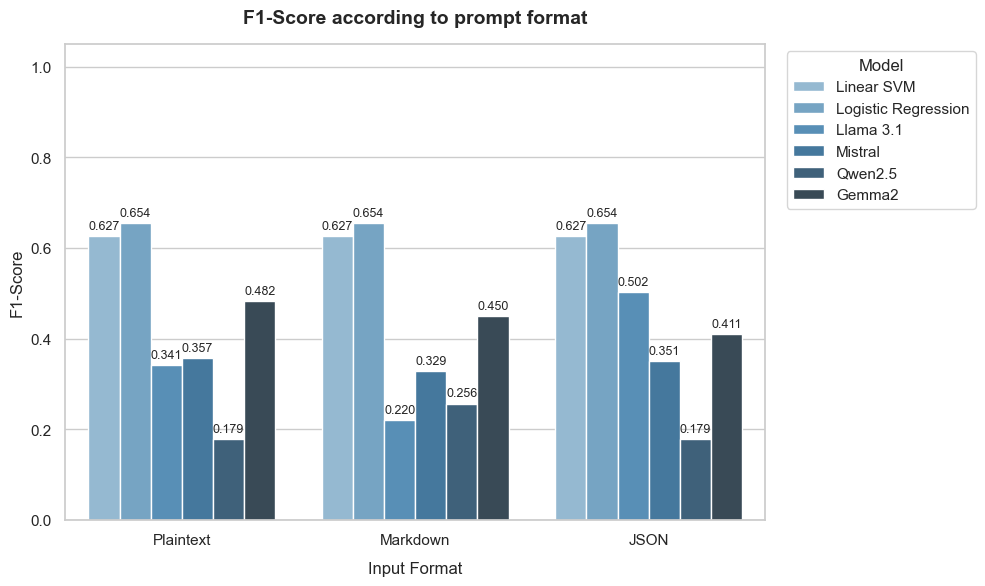

In [127]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns


sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams.update({"font.size": 11, "font.family": "sans-serif"})

plt.figure(figsize=(10, 6))

ax1 = sns.barplot(
    data=df_metrics_total,
    x="Format",
    y="F1-Score",
    hue="Model",
    palette="Blues_d",
)

plt.title("F1-Score according to prompt format", fontsize=14, fontweight="bold", pad=15)
plt.xlabel("Input Format", fontsize=12, labelpad=10)
plt.ylabel("F1-Score", fontsize=12)
plt.ylim(0, 1.05)

for p in ax1.patches:
    height = p.get_height()
    if not np.isnan(height) and height > 0:
        ax1.annotate(
            f"{height:.3f}",
            (p.get_x() + p.get_width() / 2.0, height),
            ha="center",
            va="bottom",
            fontsize=9,
            xytext=(0, 3),
            textcoords="offset points",
        )

plt.legend(title="Model", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

### Plot: Robustness metrics

C:\Users\Utente\AppData\Local\Temp\ipykernel_12032\2853790873.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
C:\Users\Utente\AppData\Local\Temp\ipykernel_12032\2853790873.py:17: UserWarning: 
The palette list has fewer values (3) than needed (4) and will cycle, which may produce an uninterpretable plot.
  sns.barplot(
C:\Users\Utente\AppData\Local\Temp\ipykernel_12032\2853790873.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
C:\Users\Utente\AppData\Local\Temp\ipykernel_12032\2853790873.py:32: UserWarning: 
The palette list has fewer values (3) than needed (4) and will cycle, which may produce an uninterpretable plot.
  sns.barplot(
C:\Users\Utente\AppData\Local\Temp\ipykernel

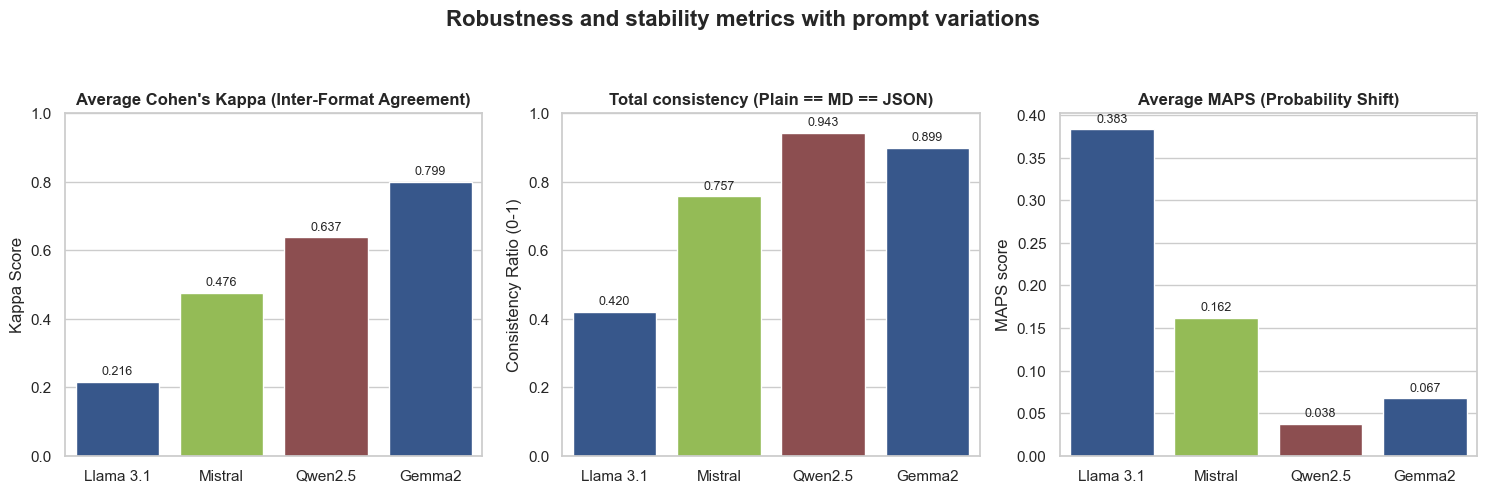

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

# Griglia 1D (1 riga, 3 colonne)
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.suptitle(
    "Robustness and stability metrics with prompt variations",
    fontsize=16,
    fontweight="bold",
    y=0.98,
)

llm_colors = ["#295499", "#98CC45", "#964447"]

# --- 1. Average Cohen Kappa ---
sns.barplot(
    data=df_kappa,
    x="Model",
    y="Average_Kappa",
    ax=axes[0],
    palette=llm_colors,
)
axes[0].set_title(
    "Average Cohen's Kappa (Inter-Format Agreement)", fontweight="bold"
)
axes[0].set_ylabel("Kappa Score")
axes[0].set_ylim(0, 1)
axes[0].set_xlabel("")

# --- 2. Total consistency ---
sns.barplot(
    data=df_consistency,
    x="Model",
    y="C_Total",
    ax=axes[1],
    palette=llm_colors,
)
axes[1].set_title(
    "Total consistency (Plain == MD == JSON)", fontweight="bold"
)
axes[1].set_ylabel("Consistency Ratio (0-1)")
axes[1].set_ylim(0, 1)
axes[1].set_xlabel("")

# --- 3. Average MAPS ---
sns.barplot(
    data=df_maps, x="Model", y="Average_MAPS", ax=axes[2], palette=llm_colors
)
axes[2].set_title("Average MAPS (Probability Shift)", fontweight="bold")
axes[2].set_ylabel("MAPS score")
axes[2].set_xlabel("")


for ax in axes.flat:
  for p in ax.patches:
    h = p.get_height()
    if not np.isnan(h):
      ax.annotate(
          f"{h:.3f}",
          (p.get_x() + p.get_width() / 2.0, h),
          ha="center",
          va="bottom",
          fontsize=9,
          xytext=(0, 3),
          textcoords="offset points",
      )

plt.tight_layout(rect=[0, 0, 1, 0.92])
plt.show()